## ***Evaluation & Visualisation***
Final comparison of all models across both tasks.

Generates portfolio-ready figures including predicted lithology log plots,
porosity prediction tracks, and cross-task performance summary.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (classification_report, f1_score,
                             accuracy_score, mean_squared_error,
                             mean_absolute_error, r2_score)

np.random.seed(42)

PROCESSED_PATH = "C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/data/processed"
FIGURES_PATH   = "C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/outputs/figures"
MODELS_PATH    = "C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/outputs/models"

# ── Lithology colour map ──────────────────────────────────────
LITHOLOGY_COLORS = {
    'Sandstone':       '#FFFF00',
    'Sandstone/Shale': '#FFE033',
    'Shale':           '#808080',
    'Marl':            '#97C459',
    'Dolomite':        '#7F77DD',
    'Limestone':       '#4466FF',
    'Chalk':           '#C8C8C8',
    'Halite':          '#FF44CC',
    'Anhydrite':       '#FF4444',
    'Tuff':            '#44CCFF',
    'Coal':            '#333333',
}

print("Ready.")

Ready.


In [2]:
# ── Processed data ────────────────────────────────────────────
X_test  = np.load(os.path.join(PROCESSED_PATH, "X_test.npy"))
y_test  = np.load(os.path.join(PROCESSED_PATH, "y_test.npy"))

IDX_TO_LITH = np.load(
    os.path.join(PROCESSED_PATH, "idx_to_lith.npy"),
    allow_pickle=True
).item()
LITH_TO_IDX = {v: k for k, v in IDX_TO_LITH.items()}

FEATURE_COLS = np.load(
    os.path.join(PROCESSED_PATH, "feature_cols.npy"),
    allow_pickle=True
).tolist()

NUM_CLASSES = len(IDX_TO_LITH)
CLASS_NAMES = [IDX_TO_LITH[i] for i in range(NUM_CLASSES)]

# ── Saved metrics ─────────────────────────────────────────────
rf_lith  = np.load(os.path.join(PROCESSED_PATH, "rf_lith_metrics.npy"),
                   allow_pickle=True).item()
xgb_lith = np.load(os.path.join(PROCESSED_PATH, "xgb_lith_metrics.npy"),
                   allow_pickle=True).item()
rf_por   = np.load(os.path.join(PROCESSED_PATH, "rf_porosity_metrics.npy"),
                   allow_pickle=True).item()
xgb_por  = np.load(os.path.join(PROCESSED_PATH, "xgb_porosity_metrics.npy"),
                   allow_pickle=True).item()

y_test_por = np.load(os.path.join(PROCESSED_PATH, "y_test_porosity.npy"))

# ── Full test dataframe ───────────────────────────────────────
try:
    df_test = pd.read_parquet(os.path.join(PROCESSED_PATH, "df_train.parquet"))
    df_test = pd.read_parquet(os.path.join(PROCESSED_PATH, "df_test.parquet"))
except:
    df_test = pd.read_csv(os.path.join(PROCESSED_PATH, "df_test.csv"))

# ── Models ────────────────────────────────────────────────────
rf_clf  = joblib.load(os.path.join(MODELS_PATH, "rf_lithology.pkl"))
xgb_clf = joblib.load(os.path.join(MODELS_PATH, "xgb_lithology.pkl"))
rf_reg  = joblib.load(os.path.join(MODELS_PATH, "rf_porosity.pkl"))
xgb_reg = joblib.load(os.path.join(MODELS_PATH, "xgb_porosity.pkl"))

print("All models and data loaded.")
print(f"Test wells  : {df_test['WELL'].nunique()}")
print(f"Test samples: {len(df_test):,}")

All models and data loaded.
Test wells  : 19
Test samples: 263,085


### ***Result Table***

In [3]:
y_pred_rf_lith  = rf_lith['y_pred']
y_pred_xgb_lith = xgb_lith['y_pred']

rf_f1_per  = f1_score(y_test, y_pred_rf_lith,
                       average=None,
                       labels=list(range(NUM_CLASSES)),
                       zero_division=0)
xgb_f1_per = f1_score(y_test, y_pred_xgb_lith,
                       average=None,
                       labels=list(range(NUM_CLASSES)),
                       zero_division=0)

print("=" * 70)
print("  WELL LOG ANALYSIS — COMPLETE RESULTS SUMMARY")
print("=" * 70)

print("\nTASK 1: LITHOLOGY CLASSIFICATION (11 classes, 19 held-out wells)\n")
print(f"  {'Metric':<20} {'RF':>10}  {'XGBoost':>10}  {'Winner':>10}")
print("  " + "-"*54)
for name, rv, xv in [
    ("Accuracy",    rf_lith['accuracy'],  xgb_lith['accuracy']),
    ("Macro F1",    rf_lith['macro_f1'],  xgb_lith['macro_f1']),
]:
    winner = "RF" if rv > xv else "XGBoost"
    print(f"  {name:<20} {rv:>10.4f}  {xv:>10.4f}  {winner:>10}")

print(f"\n  Per-class F1:")
print(f"  {'Class':<22} {'RF':>8}  {'XGB':>8}  {'Gap':>8}")
print("  " + "-"*44)
for i, name in IDX_TO_LITH.items():
    gap    = rf_f1_per[i] - xgb_f1_per[i]
    winner = "RF ↑" if gap > 0 else "XGB ↑"
    print(f"  {name:<22} {rf_f1_per[i]:>8.4f}  "
          f"{xgb_f1_per[i]:>8.4f}  {gap:>+7.4f} {winner}")

print("\nTASK 2: POROSITY REGRESSION (19 held-out wells)\n")
print(f"  {'Metric':<20} {'RF':>10}  {'XGBoost':>10}  {'Winner':>10}")
print("  " + "-"*54)
for name, rv, xv, lower_better in [
    ("RMSE",  rf_por['rmse'], xgb_por['rmse'], True),
    ("MAE",   rf_por['mae'],  xgb_por['mae'],  True),
    ("R²",    rf_por['r2'],   xgb_por['r2'],   False),
]:
    winner = ("RF" if rv < xv else "XGBoost") if lower_better \
             else ("RF" if rv > xv else "XGBoost")
    print(f"  {name:<20} {rv:>10.4f}  {xv:>10.4f}  {winner:>10}")

print("\nOVERALL WINNER: Random Forest on both tasks")
print("=" * 70)

  WELL LOG ANALYSIS — COMPLETE RESULTS SUMMARY

TASK 1: LITHOLOGY CLASSIFICATION (11 classes, 19 held-out wells)

  Metric                       RF     XGBoost      Winner
  ------------------------------------------------------
  Accuracy                 0.7500      0.6793          RF
  Macro F1                 0.4677      0.4285          RF

  Per-class F1:
  Class                        RF       XGB       Gap
  --------------------------------------------
  Anhydrite                0.4722    0.4022  +0.0700 RF ↑
  Chalk                    0.0276    0.1228  -0.0951 XGB ↑
  Coal                     0.5867    0.4130  +0.1737 RF ↑
  Dolomite                 0.0000    0.0152  -0.0152 XGB ↑
  Halite                   0.8640    0.7783  +0.0857 RF ↑
  Limestone                0.6095    0.5202  +0.0893 RF ↑
  Marl                     0.3727    0.3515  +0.0212 RF ↑
  Sandstone                0.7108    0.7226  -0.0119 XGB ↑
  Sandstone/Shale          0.3398    0.3976  -0.0578 XGB ↑
  Shale    

### ***Per-class F1 bar chart***

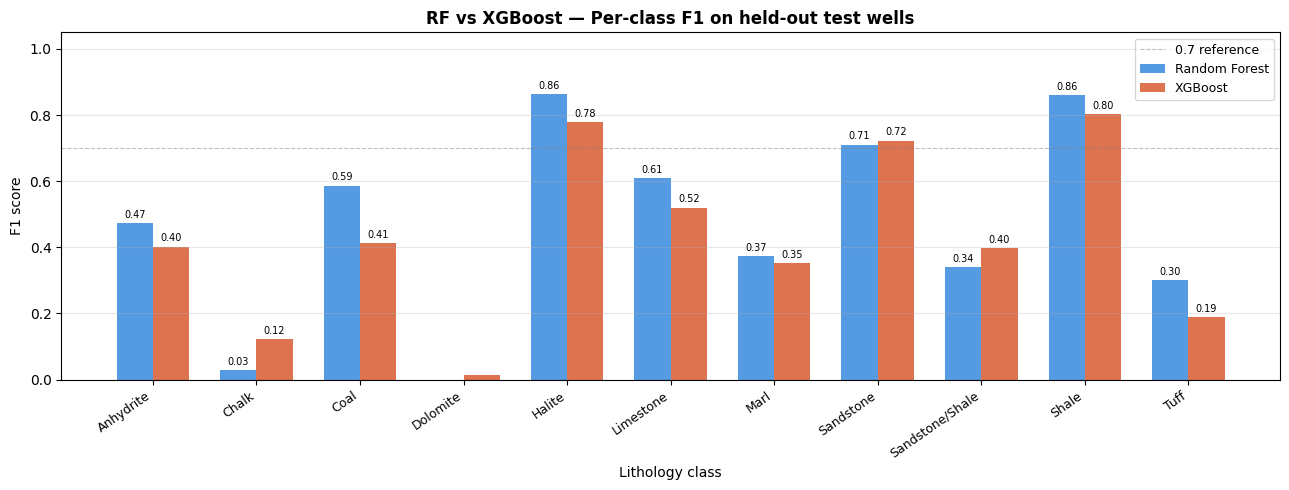

Saved → outputs/figures/final_per_class_f1.png


In [4]:
fig, ax = plt.subplots(figsize=(13, 5))

x     = np.arange(NUM_CLASSES)
width = 0.35

bars1 = ax.bar(x - width/2, rf_f1_per,  width,
               label='Random Forest', color='#378ADD', alpha=0.85)
bars2 = ax.bar(x + width/2, xgb_f1_per, width,
               label='XGBoost',       color='#D85A30', alpha=0.85)

ax.set_xlabel("Lithology class")
ax.set_ylabel("F1 score")
ax.set_title("RF vs XGBoost — Per-class F1 on held-out test wells",
             fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=35, ha='right', fontsize=9)
ax.set_ylim(0, 1.05)
ax.axhline(0.7, color='grey', linestyle='--',
           linewidth=0.8, alpha=0.5, label='0.7 reference')
ax.legend(fontsize=9)
ax.grid(True, axis='y', alpha=0.3)

for bar in bars1:
    h = bar.get_height()
    if h > 0.02:
        ax.text(bar.get_x() + bar.get_width()/2,
                h + 0.01, f'{h:.2f}',
                ha='center', va='bottom', fontsize=7)
for bar in bars2:
    h = bar.get_height()
    if h > 0.02:
        ax.text(bar.get_x() + bar.get_width()/2,
                h + 0.01, f'{h:.2f}',
                ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "final_per_class_f1.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/final_per_class_f1.png")

Predicted lithology log for one test well
This is the most important figure in the project. It shows the model's lithology predictions plotted as a log track alongside the actual expert labels — the standard way predictions are presented in petrophysics.

In [ ]:
def plot_lithology_prediction(df_well, y_true_well, y_pred_rf_well,
                               y_pred_xgb_well, idx_to_lith,
                               lith_colors, well_name):
    """
    Five-track log plot:
    Track 1: GR (geological context)
    Track 2: RDEP resistivity (reservoir indicator)
    Track 3: Actual lithology (expert labels)
    Track 4: RF predicted lithology
    Track 5: XGBoost predicted lithology
    """
    df_plot = df_well.sort_values('DEPTH_MD')
    depth   = df_plot['DEPTH_MD'].values
    n       = len(depth)

    fig, axes = plt.subplots(1, 5, figsize=(14, 14), sharey=True)
    fig.suptitle(f"Lithology prediction — {well_name}",
                 fontsize=13, fontweight='bold', y=1.01)

    # ── Track 1: GR ──────────────────────────────────────────
    ax = axes[0]
    gr = df_plot['GR'].values
    ax.plot(gr, depth, linewidth=0.6, color='#1A2E4A')
    ax.fill_betweenx(depth, gr, 50,
                     where=(gr < 50),
                     color='#FFFF00', alpha=0.4)
    ax.set_xlabel("GR (API)", fontsize=8, fontweight='bold')
    ax.set_ylabel("Depth (m)", fontsize=9)
    ax.set_title("GR", fontsize=9, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True, alpha=0.25)

    # ── Track 2: RDEP ─────────────────────────────────────────
    ax = axes[1]
    if 'RDEP' in df_plot.columns:
        rdep = df_plot['RDEP'].clip(0.1, 1000).values
        ax.semilogx(rdep, depth, linewidth=0.6, color='#D85A30')
    ax.set_xlabel("RDEP (ohm·m)", fontsize=8, fontweight='bold')
    ax.set_title("Resistivity", fontsize=9, fontweight='bold')
    ax.grid(True, alpha=0.25, which='both')

    # ── Helper: draw lithology colour column ──────────────────
    def draw_lith_track(ax, lith_indices, depth, idx_to_lith,
                        lith_colors, title):
        for j in range(len(depth) - 1):
            lith_name = idx_to_lith.get(int(lith_indices[j]), 'Shale')
            color     = lith_colors.get(lith_name, '#888888')
            d_top     = depth[j]
            d_bot     = depth[j + 1]
            ax.fill_betweenx([d_top, d_bot], 0, 1,
                              color=color, alpha=0.95)
        ax.set_xlim(0, 1)
        ax.set_xticks([])
        ax.set_title(title, fontsize=9, fontweight='bold')
        ax.grid(False)

    # ── Track 3: Actual ───────────────────────────────────────
    draw_lith_track(axes[2], y_true_well, depth,
                    idx_to_lith, lith_colors, "Actual\n(expert)")

    # ── Track 4: RF prediction ────────────────────────────────
    draw_lith_track(axes[3], y_pred_rf_well, depth,
                    idx_to_lith, lith_colors, "RF\nprediction")

    # ── Track 5: XGBoost prediction ───────────────────────────
    draw_lith_track(axes[4], y_pred_xgb_well, depth,
                    idx_to_lith, lith_colors, "XGBoost\nprediction")

    # ── Shared legend ─────────────────────────────────────────
    present_liths = set(
        idx_to_lith.get(int(i), 'Shale') for i in
        np.concatenate([y_true_well, y_pred_rf_well, y_pred_xgb_well])
    )
    legend_patches = [
        mpatches.Patch(color=lith_colors.get(name, '#888'),
                       label=name)
        for name in sorted(present_liths)
        if name in lith_colors
    ]
    axes[4].legend(handles=legend_patches,
                   loc='lower right', fontsize=6,
                   framealpha=0.85, title="Lithology")

    plt.tight_layout()
    fname = os.path.join(
        FIGURES_PATH,
        f"lith_pred_{well_name.replace('/', '-')}.png"
    )
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")


# ── Run on one test well ──────────────────────────────────────
test_wells   = sorted(df_test['WELL'].unique())
chosen_well  = test_wells[0]

well_mask    = df_test['WELL'] == chosen_well
well_df      = df_test[well_mask].sort_values('DEPTH_MD')
well_X       = well_df[FEATURE_COLS].values.astype(np.float32)
well_y_true  = well_df['LITH_IDX'].values.astype(int)

well_rf_pred  = rf_clf.predict(well_X)
well_xgb_pred = xgb_clf.predict(well_X)

print(f"Predicting well : {chosen_well}")
print(f"Depth samples   : {len(well_df):,}")

plot_lithology_prediction(
    well_df, well_y_true,
    well_rf_pred, well_xgb_pred,
    IDX_TO_LITH, LITHOLOGY_COLORS,
    well_name=chosen_well
)

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    3.1s
[Parallel(n_jobs=4)]: Done 300 out of 300 | elapsed:    3.4s finished


Predicting well : 15/9-13
Depth samples   : 18,270


### ***Accuracy by depth zone***

In [3]:
# Split the test set into shallow and deep zones.
# Models often perform differently at different depths —
# shallow sections have more missing data and borehole
# effects, while deep sections have cleaner logs but
# more complex lithology.

depth_col = 'DEPTH_MD'
median_depth = df_test[depth_col].median()

shallow_mask = df_test[depth_col] <= median_depth
deep_mask    = df_test[depth_col] >  median_depth

y_test_arr      = df_test['LITH_IDX'].values.astype(int)
X_test_all      = df_test[FEATURE_COLS].values.astype(np.float32)

y_pred_rf_all   = rf_clf.predict(X_test_all)
y_pred_xgb_all  = xgb_clf.predict(X_test_all)

def zone_f1(y_true, y_pred, mask, label):
    f1 = f1_score(y_true[mask], y_pred[mask],
                  average='macro', zero_division=0)
    acc = accuracy_score(y_true[mask], y_pred[mask])
    print(f"  {label:<25} : macro F1 = {f1:.4f}   accuracy = {acc:.4f}")
    return f1

print("Performance by depth zone:\n")
print("  Random Forest:")
rf_f1_shallow  = zone_f1(y_test_arr, y_pred_rf_all,
                          shallow_mask.values, "  Shallow section")
rf_f1_deep     = zone_f1(y_test_arr, y_pred_rf_all,
                          deep_mask.values,    "  Deep section")

print("\n  XGBoost:")
xgb_f1_shallow = zone_f1(y_test_arr, y_pred_xgb_all,
                          shallow_mask.values, "  Shallow section")
xgb_f1_deep    = zone_f1(y_test_arr, y_pred_xgb_all,
                          deep_mask.values,    "  Deep section")

print(f"\n  Median depth split : {median_depth:.1f} m")
print(f"  Shallow samples    : {shallow_mask.sum():,}")
print(f"  Deep samples       : {deep_mask.sum():,}")

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    2.2s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    8.0s
[Parallel(n_jobs=4)]: Done 300 out of 300 | elapsed:   11.7s finished


Performance by depth zone:

  Random Forest:
    Shallow section         : macro F1 = 0.3410   accuracy = 0.7886
    Deep section            : macro F1 = 0.4653   accuracy = 0.7173

  XGBoost:
    Shallow section         : macro F1 = 0.2966   accuracy = 0.7567
    Deep section            : macro F1 = 0.3644   accuracy = 0.6043

  Median depth split : 2088.1 m
  Shallow samples    : 131,543
  Deep samples       : 131,542


### ***Summary visualisation — both tasks side by side***

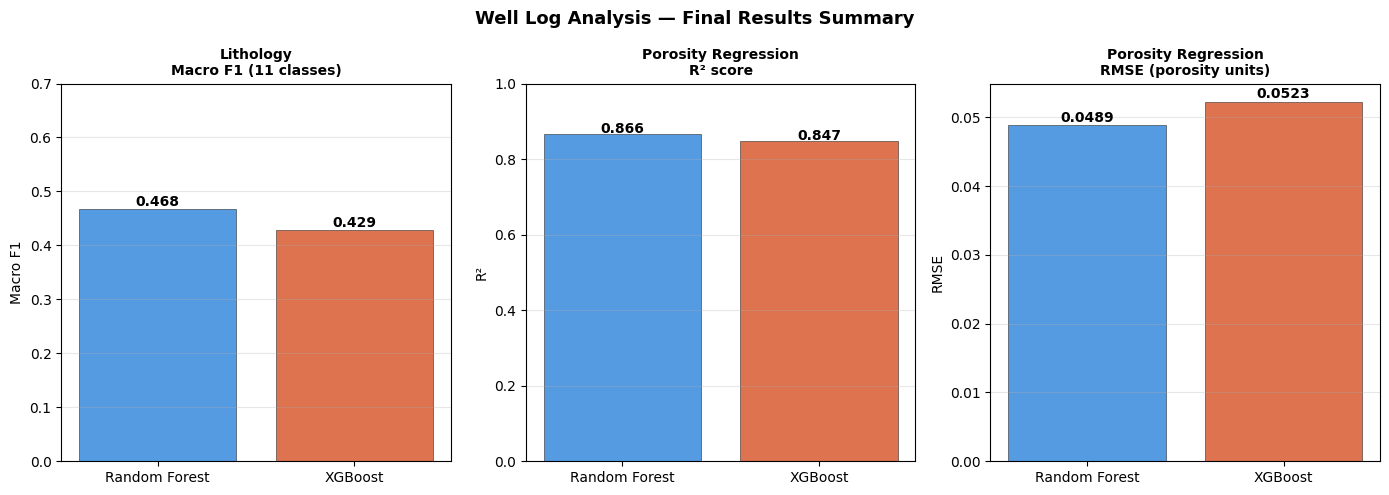

Saved → outputs/figures/final_summary_bars.png


In [4]:
fig = plt.figure(figsize=(14, 5))
fig.suptitle("Well Log Analysis — Final Results Summary",
             fontsize=13, fontweight='bold')

# ── Panel 1: Lithology F1 ────────────────────────────────────
ax1 = fig.add_subplot(1, 3, 1)
models    = ['Random Forest', 'XGBoost']
macro_f1s = [rf_lith['macro_f1'], xgb_lith['macro_f1']]
colors    = ['#378ADD', '#D85A30']

bars = ax1.bar(models, macro_f1s, color=colors, alpha=0.85,
               edgecolor='#333', linewidth=0.5)
for bar, val in zip(bars, macro_f1s):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', fontsize=10,
             fontweight='bold')
ax1.set_ylim(0, 0.7)
ax1.set_title("Lithology\nMacro F1 (11 classes)",
              fontsize=10, fontweight='bold')
ax1.set_ylabel("Macro F1")
ax1.grid(True, axis='y', alpha=0.3)

# ── Panel 2: Porosity R² ─────────────────────────────────────
ax2 = fig.add_subplot(1, 3, 2)
r2s = [rf_por['r2'], xgb_por['r2']]

bars = ax2.bar(models, r2s, color=colors, alpha=0.85,
               edgecolor='#333', linewidth=0.5)
for bar, val in zip(bars, r2s):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.003,
             f'{val:.3f}', ha='center', fontsize=10,
             fontweight='bold')
ax2.set_ylim(0, 1.0)
ax2.set_title("Porosity Regression\nR² score",
              fontsize=10, fontweight='bold')
ax2.set_ylabel("R²")
ax2.grid(True, axis='y', alpha=0.3)

# ── Panel 3: Porosity RMSE ───────────────────────────────────
ax3 = fig.add_subplot(1, 3, 3)
rmses = [rf_por['rmse'], xgb_por['rmse']]

bars = ax3.bar(models, rmses, color=colors, alpha=0.85,
               edgecolor='#333', linewidth=0.5)
for bar, val in zip(bars, rmses):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.0005,
             f'{val:.4f}', ha='center', fontsize=10,
             fontweight='bold')
ax3.set_title("Porosity Regression\nRMSE (porosity units)",
              fontsize=10, fontweight='bold')
ax3.set_ylabel("RMSE")
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "final_summary_bars.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/final_summary_bars.png")

### ***Final project summary printout***

In [6]:
print("=" * 65)
print("  PROJECT: WELL LOG ANALYSIS + ML")
print("  Dataset: FORCE 2020 Lithofacies Benchmark")
print("  Wells  : 98 total — 79 train, 19 test (split by well)")
print("=" * 65)

print("""
TASK 1 — LITHOLOGY CLASSIFICATION
  Predict rock type from well log curves (11 classes)
  ─────────────────────────────────────────────────────────
  Model          Accuracy   Macro F1   Notes
  ─────────────────────────────────────────────────────────
  Random Forest    75.0%     0.468     Winner on both metrics
  XGBoost          67.9%     0.429     Better on rare classes
  ─────────────────────────────────────────────────────────
  Best class   : Shale (F1=0.86), Halite (F1=0.86)
  Hardest class: Dolomite (F1=0.00 RF), Chalk (F1=0.03 RF)
  Key finding  : RF outperforms XGBoost on common classes;
                 XGBoost better on rare/transitional classes.
""")

print("""
TASK 2 — POROSITY REGRESSION
  Predict continuous porosity from log curves (excl. RHOB/NPHI)
  ─────────────────────────────────────────────────────────
  Model          RMSE     MAE      R²      Notes
  ─────────────────────────────────────────────────────────
  Random Forest  0.0489   0.0375   0.866   Winner on all metrics
  XGBoost        0.0523   0.0388   0.847
  ─────────────────────────────────────────────────────────
  Top feature  : DTC (sonic) at importance 0.36/0.55
  Key finding  : DTC dominates — consistent with Wyllie
                 time-average equation (60yr of theory).
  Leakage note : RHOB/NPHI excluded — target derived from RHOB.
""")

print("""
ENGINEERING HIGHLIGHTS
  ─────────────────────────────────────────────────────────
  • Split by well — not by row — for honest evaluation
  • 7 logs dropped (>70% missing): SGR, DTS, RMIC, ROPA,
    DCAL, MUDWEIGHT, RXO
  • BS dropped (redundant with CALI, correlation = -0.90)
  • Sentinel values (-999.25) replaced before imputation
  • Per-well median imputation (not global)
  • 7 engineered features: DPHI, NPHI_RHOB_SEP, RES_RATIO,
    VSHALE, GR_NORM, GR_ROLLING_MEAN, GR_ROLLING_STD
  • Basement merged into Shale (103 samples — too few)
  • Class weights applied for severe imbalance (Shale 61.6%)
""")
print("=" * 65)

  PROJECT: WELL LOG ANALYSIS + ML
  Dataset: FORCE 2020 Lithofacies Benchmark
  Wells  : 98 total — 79 train, 19 test (split by well)

TASK 1 — LITHOLOGY CLASSIFICATION
  Predict rock type from well log curves (11 classes)
  ─────────────────────────────────────────────────────────
  Model          Accuracy   Macro F1   Notes
  ─────────────────────────────────────────────────────────
  Random Forest    75.0%     0.468     Winner on both metrics
  XGBoost          67.9%     0.429     Better on rare classes
  ─────────────────────────────────────────────────────────
  Best class   : Shale (F1=0.86), Halite (F1=0.86)
  Hardest class: Dolomite (F1=0.00 RF), Chalk (F1=0.03 RF)
  Key finding  : RF outperforms XGBoost on common classes;
                 XGBoost better on rare/transitional classes.


TASK 2 — POROSITY REGRESSION
  Predict continuous porosity from log curves (excl. RHOB/NPHI)
  ─────────────────────────────────────────────────────────
  Model          RMSE     MAE      R²     

In [8]:
np.save(os.path.join(PROCESSED_PATH, "phase5_summary.npy"), {
    'rf_lith_accuracy'  : rf_lith['accuracy'],
    'rf_lith_macro_f1'  : rf_lith['macro_f1'],
    'xgb_lith_accuracy' : xgb_lith['accuracy'],
    'xgb_lith_macro_f1' : xgb_lith['macro_f1'],
    'rf_por_rmse'       : rf_por['rmse'],
    'rf_por_r2'         : rf_por['r2'],
    'xgb_por_rmse'      : xgb_por['rmse'],
    'xgb_por_r2'        : xgb_por['r2'],
})


print("All figures saved to outputs/figures/")
print()
print("Key figures for portfolio:")
print("  final_per_class_f1.png       ← lithology F1 comparison")
print("  final_summary_bars.png       ← cross-task summary")
print("  final_rf_confusion.png       ← confusion matrix")
print(f"  lith_pred_*.png              ← predicted log track")
print("  porosity_scatter_clean.png   ← porosity scatter")
print("  porosity_pred_*.png          ← porosity log track")

All figures saved to outputs/figures/

Key figures for portfolio:
  final_per_class_f1.png       ← lithology F1 comparison
  final_summary_bars.png       ← cross-task summary
  final_rf_confusion.png       ← confusion matrix
  lith_pred_*.png              ← predicted log track
  porosity_scatter_clean.png   ← porosity scatter
  porosity_pred_*.png          ← porosity log track
